# 02 — Exploratory Data Analysis (EDA)

**Objective:** Understand the structure, distributions, correlations, and temporal patterns in the processed malaria indicators dataset before feature engineering and modeling.

**Input:** `data/processed/malaria_indicators_wide.csv`  
**Output:** Charts saved to `reports/figures/` + documented observations that guide notebook 03

## 1. Imports & Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import os

# Plot style
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
FIGURES_PATH = '../reports/figures/'
os.makedirs(FIGURES_PATH, exist_ok=True)

RISK_PALETTE = {'Low': '#2ecc71', 'Medium': '#f39c12', 'High': '#e74c3c'}
RISK_ORDER   = ['Low', 'Medium', 'High']

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)

## 2. Load Processed Data

In [2]:
df = pd.read_csv('../data/processed/malaria_indicators_wide.csv')

# Working subset: rows where RDT prevalence is available (2015, 2018, 2021 only)
df_model = df[df['prevalence_rdt'].notna()].copy()

print(f'Full dataset:    {df.shape}')
print(f'Modeling subset: {df_model.shape}')
print(f'Survey years in model subset: {sorted(df_model["SurveyYear"].unique())}')

Full dataset:    (185, 20)
Modeling subset: (111, 20)
Survey years in model subset: [np.int64(2015), np.int64(2018), np.int64(2021)]


## 3. Target Variable Distribution

Understand the distribution of our target (`risk_class`) and the raw prevalence values.

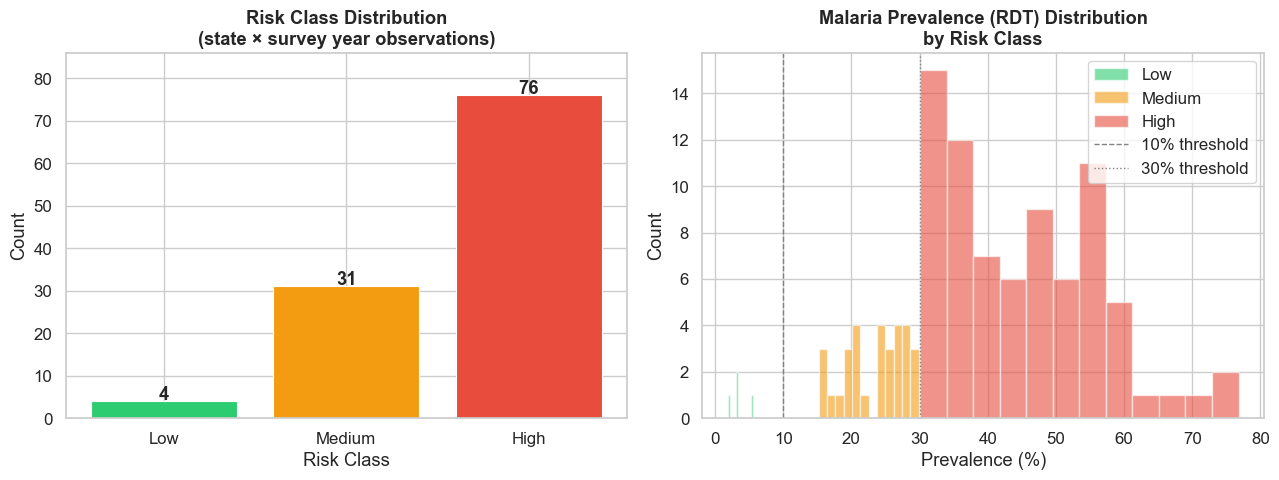


Key observation: Strong class imbalance — High dominates.
Low class has only 4 samples — consider merging Low+Medium in modeling.


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# --- Left: Risk class counts ---
risk_counts = df_model['risk_class'].value_counts().reindex(RISK_ORDER)
axes[0].bar(risk_counts.index, risk_counts.values,
            color=[RISK_PALETTE[r] for r in risk_counts.index], edgecolor='white', linewidth=0.8)
for i, v in enumerate(risk_counts.values):
    axes[0].text(i, v + 0.5, str(v), ha='center', fontweight='bold')
axes[0].set_title('Risk Class Distribution\n(state × survey year observations)', fontweight='bold')
axes[0].set_xlabel('Risk Class')
axes[0].set_ylabel('Count')
axes[0].set_ylim(0, risk_counts.max() + 10)

# --- Right: RDT prevalence histogram by risk class ---
for rc in RISK_ORDER:
    subset = df_model[df_model['risk_class'] == rc]['prevalence_rdt']
    axes[1].hist(subset, bins=12, alpha=0.6, color=RISK_PALETTE[rc], label=rc, edgecolor='white')
axes[1].axvline(10, color='grey', linestyle='--', linewidth=1, label='10% threshold')
axes[1].axvline(30, color='grey', linestyle=':', linewidth=1, label='30% threshold')
axes[1].set_title('Malaria Prevalence (RDT) Distribution\nby Risk Class', fontweight='bold')
axes[1].set_xlabel('Prevalence (%)')
axes[1].set_ylabel('Count')
axes[1].legend()

plt.tight_layout()
plt.savefig(FIGURES_PATH + '01_target_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

print('\nKey observation: Strong class imbalance — High dominates.')
print('Low class has only 4 samples — consider merging Low+Medium in modeling.')

## 4. Risk Class Trends Over Time

How has the distribution of risk classes shifted between 2015, 2018, and 2021?

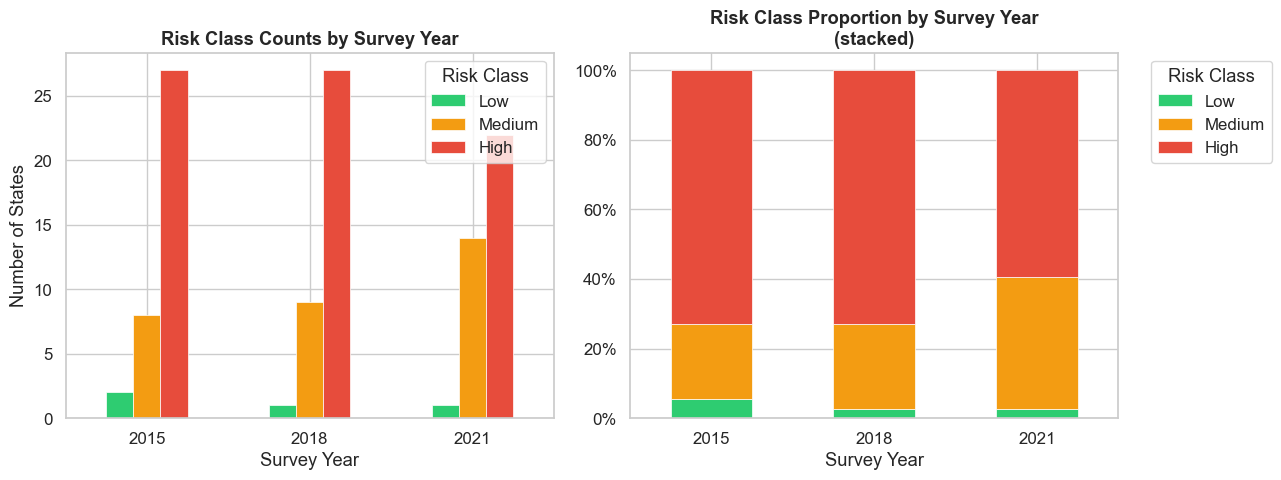


Trend: High risk declining, Medium risk growing — reflects Nigeria malaria program progress.


In [4]:
year_risk = (df_model
             .groupby(['SurveyYear', 'risk_class'])
             .size()
             .unstack(fill_value=0)
             .reindex(columns=RISK_ORDER, fill_value=0))

year_risk_pct = year_risk.div(year_risk.sum(axis=1), axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# --- Left: Raw counts ---
year_risk.plot(kind='bar', ax=axes[0],
               color=[RISK_PALETTE[r] for r in RISK_ORDER],
               edgecolor='white', linewidth=0.5)
axes[0].set_title('Risk Class Counts by Survey Year', fontweight='bold')
axes[0].set_xlabel('Survey Year')
axes[0].set_ylabel('Number of States')
axes[0].legend(title='Risk Class')
axes[0].tick_params(axis='x', rotation=0)

# --- Right: Proportions ---
year_risk_pct.plot(kind='bar', stacked=True, ax=axes[1],
                   color=[RISK_PALETTE[r] for r in RISK_ORDER],
                   edgecolor='white', linewidth=0.5)
axes[1].set_title('Risk Class Proportion by Survey Year\n(stacked)', fontweight='bold')
axes[1].set_xlabel('Survey Year')
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter())
axes[1].legend(title='Risk Class', bbox_to_anchor=(1.05, 1))
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.savefig(FIGURES_PATH + '02_risk_trends_by_year.png', dpi=150, bbox_inches='tight')
plt.show()

print('\nTrend: High risk declining, Medium risk growing — reflects Nigeria malaria program progress.')

## 5. Prevalence by State (Most Recent Survey)

Which states carry the highest malaria burden in the most recent data (2021)?

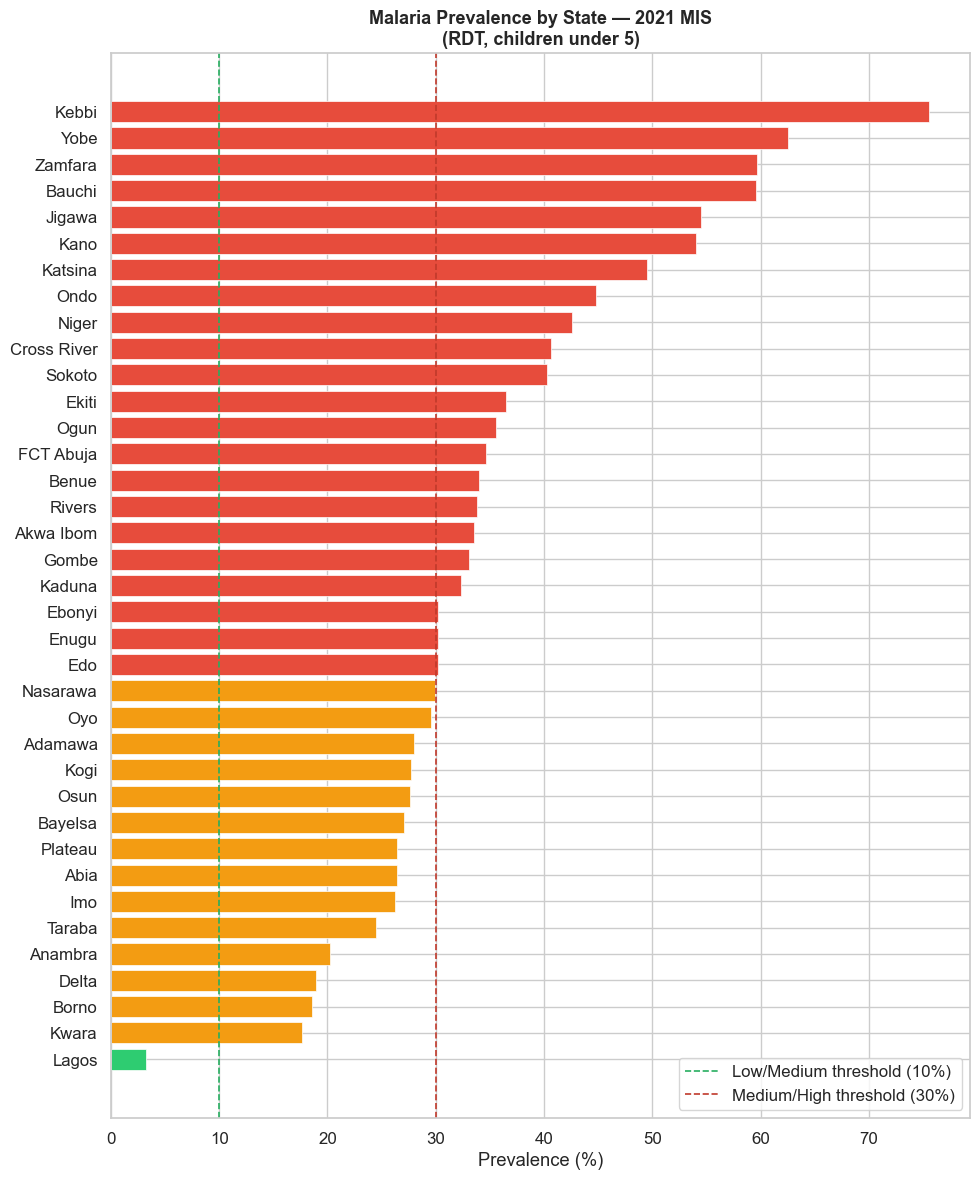

In [5]:
df_2021 = df_model[df_model['SurveyYear'] == 2021].sort_values('prevalence_rdt', ascending=True)

fig, ax = plt.subplots(figsize=(10, 12))

colors = [RISK_PALETTE.get(rc, 'grey') for rc in df_2021['risk_class']]
bars = ax.barh(df_2021['Location'], df_2021['prevalence_rdt'],
               color=colors, edgecolor='white', linewidth=0.5)

ax.axvline(10, color='#27ae60', linestyle='--', linewidth=1.2, label='Low/Medium threshold (10%)')
ax.axvline(30, color='#c0392b', linestyle='--', linewidth=1.2, label='Medium/High threshold (30%)')

ax.set_title('Malaria Prevalence by State — 2021 MIS\n(RDT, children under 5)', fontweight='bold', fontsize=13)
ax.set_xlabel('Prevalence (%)')
ax.set_ylabel('')
ax.legend(loc='lower right')

plt.tight_layout()
plt.savefig(FIGURES_PATH + '03_prevalence_by_state_2021.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. Intervention Coverage vs. Prevalence

The core hypothesis: states with higher ITN coverage and ANC intervention rates should have lower malaria prevalence. Let's check whether the data supports this.

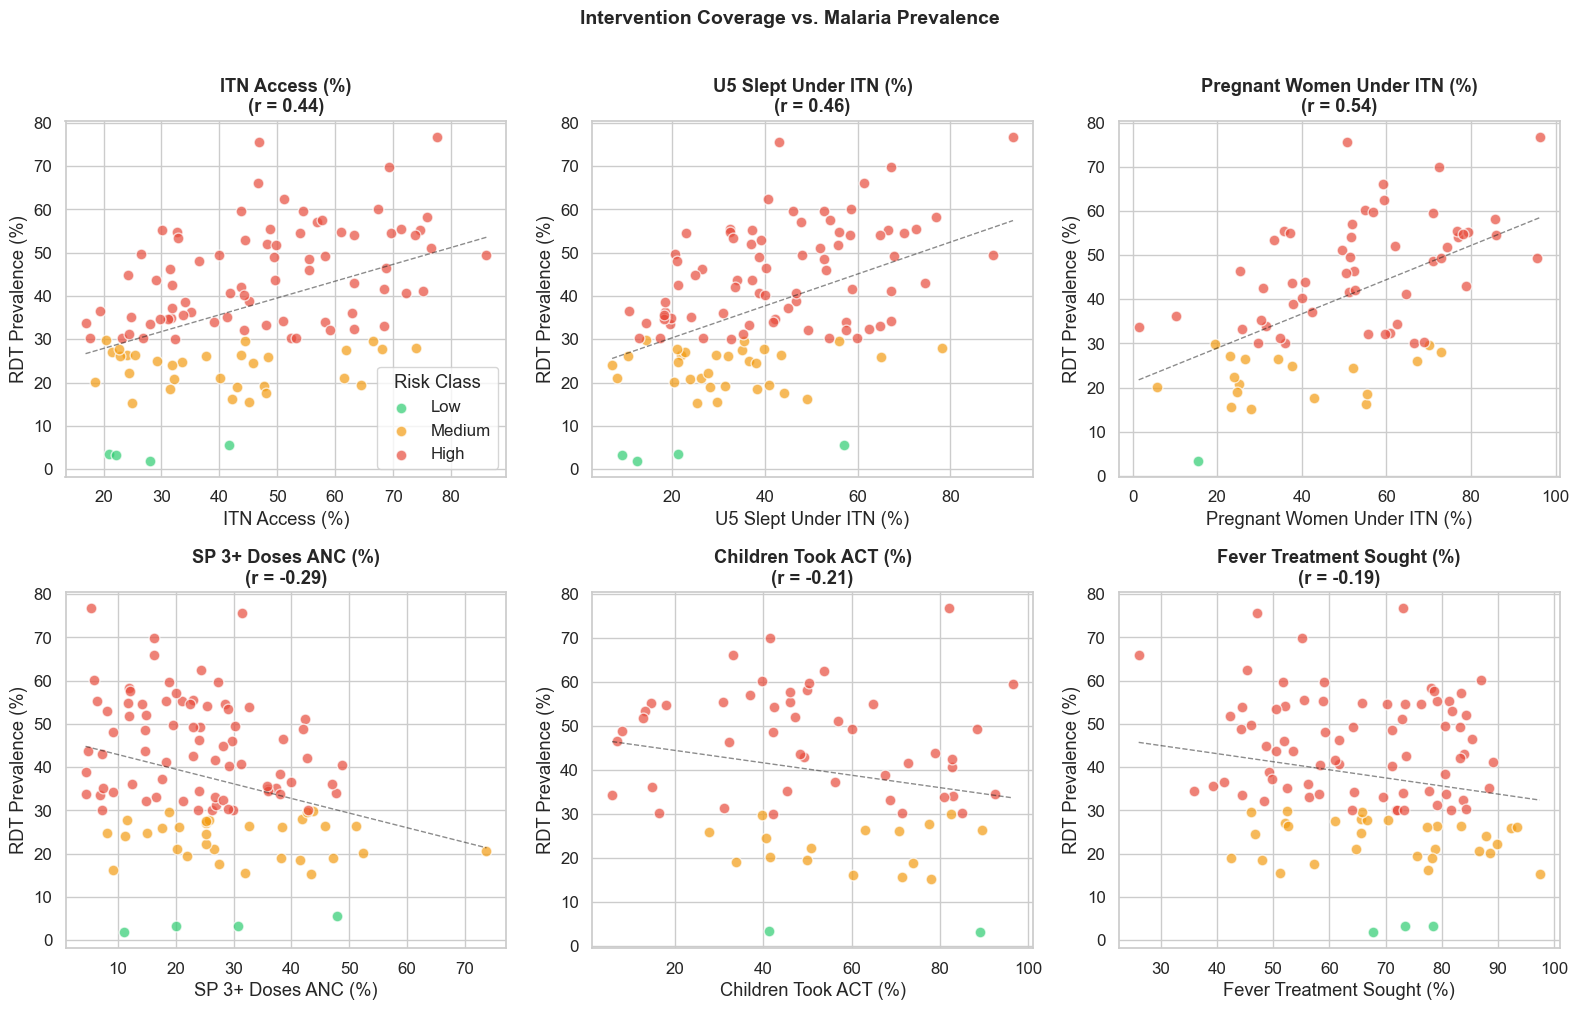


Observations to note:
- Negative correlations (ITN access/usage) confirm protective effect
- Weak or positive correlations for treatment indicators suggest endogeneity
  (high-prevalence states may also have higher treatment-seeking rates)


In [6]:
INTERVENTION_COLS = [
    'itn_access', 'itn_slept_u5', 'itn_slept_preg',
    'sp_3plus_doses', 'act_treatment', 'fever_treatment_sought'
]

LABELS = {
    'itn_access': 'ITN Access (%)',
    'itn_slept_u5': 'U5 Slept Under ITN (%)',
    'itn_slept_preg': 'Pregnant Women Under ITN (%)',
    'sp_3plus_doses': 'SP 3+ Doses ANC (%)',
    'act_treatment': 'Children Took ACT (%)',
    'fever_treatment_sought': 'Fever Treatment Sought (%)'
}

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, col in enumerate(INTERVENTION_COLS):
    subset = df_model[['prevalence_rdt', col, 'risk_class', 'SurveyYear']].dropna()
    for rc in RISK_ORDER:
        s = subset[subset['risk_class'] == rc]
        axes[i].scatter(s[col], s['prevalence_rdt'],
                        color=RISK_PALETTE[rc], label=rc, alpha=0.7, edgecolors='white', s=60)

    # Trend line
    if len(subset) > 3:
        z = np.polyfit(subset[col].dropna(), subset.loc[subset[col].notna(), 'prevalence_rdt'], 1)
        p = np.poly1d(z)
        x_line = np.linspace(subset[col].min(), subset[col].max(), 100)
        axes[i].plot(x_line, p(x_line), 'k--', linewidth=1, alpha=0.5)

    corr = subset[[col, 'prevalence_rdt']].corr().iloc[0, 1]
    axes[i].set_title(f'{LABELS[col]}\n(r = {corr:.2f})', fontweight='bold')
    axes[i].set_xlabel(LABELS[col])
    axes[i].set_ylabel('RDT Prevalence (%)')
    if i == 0:
        axes[i].legend(title='Risk Class')

plt.suptitle('Intervention Coverage vs. Malaria Prevalence', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(FIGURES_PATH + '04_interventions_vs_prevalence.png', dpi=150, bbox_inches='tight')
plt.show()

print('\nObservations to note:')
print('- Negative correlations (ITN access/usage) confirm protective effect')
print('- Weak or positive correlations for treatment indicators suggest endogeneity')
print('  (high-prevalence states may also have higher treatment-seeking rates)')

## 7. Correlation Heatmap

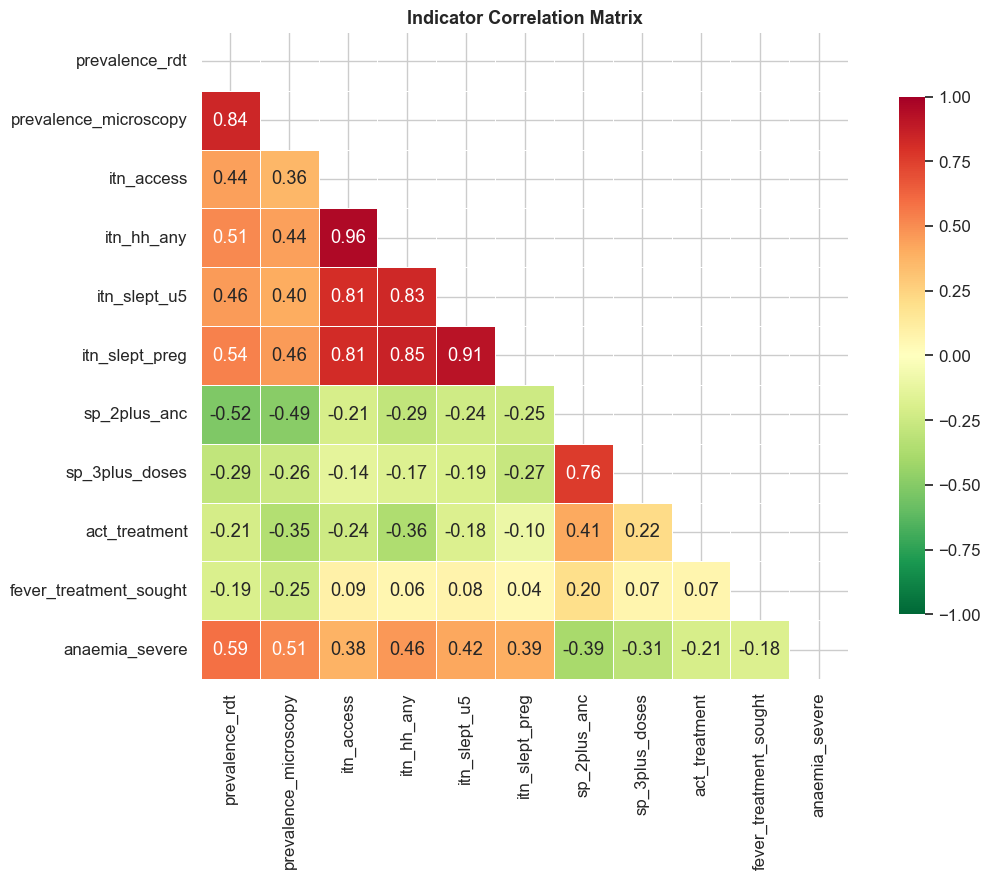

In [7]:
NUMERIC_COLS = [
    'prevalence_rdt', 'prevalence_microscopy',
    'itn_access', 'itn_hh_any', 'itn_slept_u5', 'itn_slept_preg',
    'sp_2plus_anc', 'sp_3plus_doses',
    'act_treatment', 'fever_treatment_sought', 'anaemia_severe'
]

corr_matrix = df_model[NUMERIC_COLS].corr()

fig, ax = plt.subplots(figsize=(12, 9))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f',
            cmap='RdYlGn_r', center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5, ax=ax,
            cbar_kws={'shrink': 0.8})
ax.set_title('Indicator Correlation Matrix', fontweight='bold', fontsize=13)
plt.tight_layout()
plt.savefig(FIGURES_PATH + '05_correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

## 8. Missingness Analysis

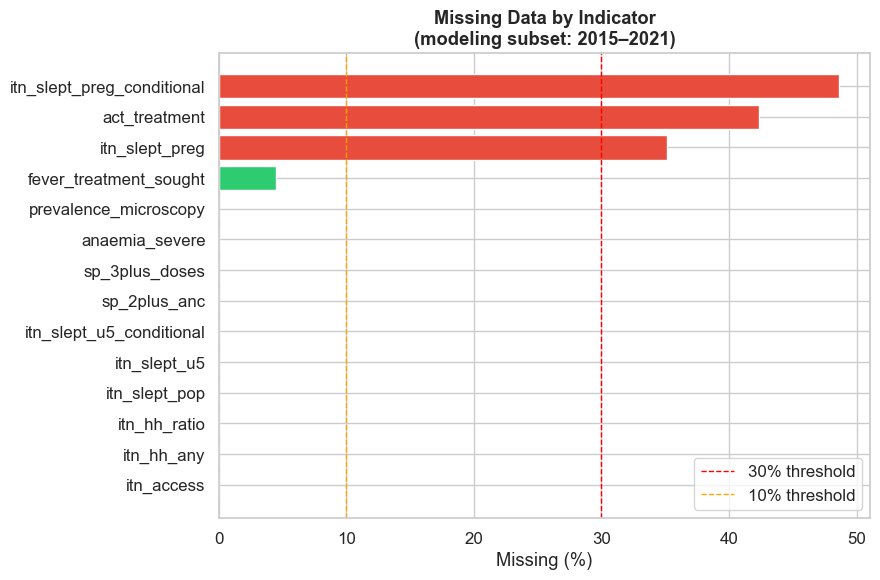


=== MISSINGNESS SUMMARY ===
itn_access                    0.00
itn_hh_any                    0.00
itn_hh_ratio                  0.00
itn_slept_pop                 0.00
itn_slept_u5                  0.00
itn_slept_u5_conditional      0.00
sp_2plus_anc                  0.00
sp_3plus_doses                0.00
anaemia_severe                0.00
prevalence_microscopy         0.00
fever_treatment_sought        4.50
itn_slept_preg               35.10
act_treatment                42.30
itn_slept_preg_conditional   48.60


In [8]:
FEATURE_COLS = [
    'itn_access', 'itn_hh_any', 'itn_hh_ratio',
    'itn_slept_pop', 'itn_slept_u5', 'itn_slept_u5_conditional',
    'itn_slept_preg', 'itn_slept_preg_conditional',
    'sp_2plus_anc', 'sp_3plus_doses',
    'act_treatment', 'fever_treatment_sought',
    'anaemia_severe', 'prevalence_microscopy'
]

missing_pct = df_model[FEATURE_COLS].isnull().mean() * 100
missing_pct = missing_pct.sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(9, 6))
colors = ['#e74c3c' if v > 30 else '#f39c12' if v > 10 else '#2ecc71'
          for v in missing_pct.values]
ax.barh(missing_pct.index, missing_pct.values, color=colors, edgecolor='white')
ax.axvline(30, color='red', linestyle='--', linewidth=1, label='30% threshold')
ax.axvline(10, color='orange', linestyle='--', linewidth=1, label='10% threshold')
ax.set_title('Missing Data by Indicator\n(modeling subset: 2015–2021)', fontweight='bold')
ax.set_xlabel('Missing (%)')
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_PATH + '06_missingness.png', dpi=150, bbox_inches='tight')
plt.show()

print('\n=== MISSINGNESS SUMMARY ===')
print(missing_pct.round(1).to_string())

## 9. Prevalence Change Over Time — State Trajectories

Track individual state trajectories across 2015 → 2018 → 2021. States moving in unexpected directions are candidates for the reporting reliability flag.

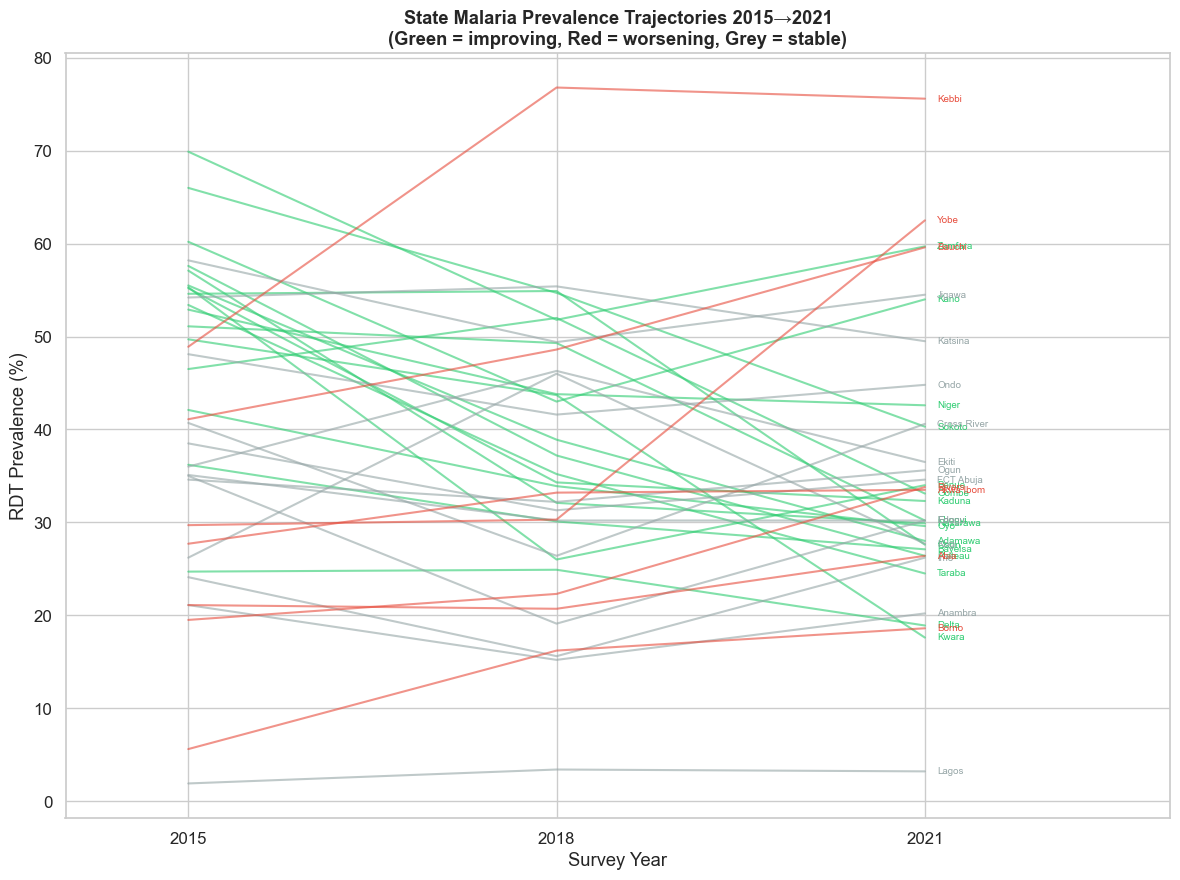

In [9]:
pivot_traj = df_model.pivot_table(
    index='Location', columns='SurveyYear', values='prevalence_rdt'
)

# States present in all three years
pivot_traj = pivot_traj.dropna()

# Compute change 2015 -> 2021
pivot_traj['change'] = pivot_traj[2021] - pivot_traj[2015]
pivot_traj = pivot_traj.sort_values('change')

fig, ax = plt.subplots(figsize=(12, 9))

for state in pivot_traj.index:
    years = [2015, 2018, 2021]
    vals  = pivot_traj.loc[state, years].values
    color = '#e74c3c' if pivot_traj.loc[state, 'change'] > 5 else \
            '#2ecc71' if pivot_traj.loc[state, 'change'] < -5 else '#95a5a6'
    ax.plot(years, vals, color=color, alpha=0.6, linewidth=1.5)
    ax.text(2021.1, vals[-1], state, fontsize=7, va='center', color=color)

ax.set_xlim(2014, 2023)
ax.set_xticks([2015, 2018, 2021])
ax.set_title('State Malaria Prevalence Trajectories 2015→2021\n'
             '(Green = improving, Red = worsening, Grey = stable)', fontweight='bold')
ax.set_xlabel('Survey Year')
ax.set_ylabel('RDT Prevalence (%)')

plt.tight_layout()
plt.savefig(FIGURES_PATH + '07_state_trajectories.png', dpi=150, bbox_inches='tight')
plt.show()

## 10. EDA Summary — Key Observations

Document the findings that will directly drive decisions in notebook 03 (feature engineering).

In [10]:
print("""
=== EDA KEY FINDINGS ===

1. TARGET VARIABLE
   - Strong class imbalance: High (68%) >> Medium (28%) >> Low (4%)
   - Consider merging Low + Medium into a single class for modeling
   - RDT data only available for 2015, 2018, 2021 (111 usable rows)

2. TEMPORAL TREND
   - High-risk states declining over time (27 → 22 from 2015 → 2021)
   - Survey year must be included as a feature to capture this trend

3. INTERVENTION INDICATORS
   - ITN access and U5 ITN usage show negative correlation with prevalence (protective effect confirmed)
   - Treatment indicators (ACT, fever treatment) show weak/mixed correlation — endogeneity risk
   - Highly correlated ITN sub-indicators: consider selecting 1-2 to reduce multicollinearity

4. MISSINGNESS
   - Some indicators have >30% missing in the modeling subset
   - High-missingness indicators: flag as low-reliability features, impute carefully or drop
   - Missingness is not random — older surveys lack some indicators entirely

5. STATE TRAJECTORIES
   - Most states improving or stable 2015 → 2021
   - A minority of states show rising prevalence — these are candidates for reliability flagging
   - Sudden jumps between survey years may reflect data quality issues, not true epidemiological change

6. FEATURE ENGINEERING PRIORITIES (→ Notebook 03)
   - Create composite ITN coverage score (reduce redundancy)
   - Create ANC intervention composite score
   - Add SurveyYear as numeric feature
   - Add prevalence lag (previous survey year's value) as a feature where available
   - Flag states with high variance across years as a reliability signal
""")


=== EDA KEY FINDINGS ===

1. TARGET VARIABLE
   - Strong class imbalance: High (68%) >> Medium (28%) >> Low (4%)
   - Consider merging Low + Medium into a single class for modeling
   - RDT data only available for 2015, 2018, 2021 (111 usable rows)

2. TEMPORAL TREND
   - High-risk states declining over time (27 → 22 from 2015 → 2021)
   - Survey year must be included as a feature to capture this trend

3. INTERVENTION INDICATORS
   - ITN access and U5 ITN usage show negative correlation with prevalence (protective effect confirmed)
   - Treatment indicators (ACT, fever treatment) show weak/mixed correlation — endogeneity risk
   - Highly correlated ITN sub-indicators: consider selecting 1-2 to reduce multicollinearity

4. MISSINGNESS
   - Some indicators have >30% missing in the modeling subset
   - High-missingness indicators: flag as low-reliability features, impute carefully or drop
   - Missingness is not random — older surveys lack some indicators entirely

5. STATE TRAJECTORIES